# Descriptive premise analysis

In [48]:
from typing import Dict
from unittest.mock import inplace

import pandas as pd
import numpy as np

import torch
import functional as pyf

In [49]:
JSON_STRUCTURE_PATH = "document_data_parsing/{doc_id}.json"

In [50]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

## Downloading Document Parsing

In [51]:
from pathlib import Path
import json

In [52]:
def read_json_file(path: str):
    with open(path, "r") as doc_file:
        doc_file_contents = json.loads(doc_file.read())

    return doc_file_contents

In [53]:
def read_structures(doc_list: list[str]) -> dict:
    docs = {}
    for doc_id in doc_list:
        doc_path = JSON_STRUCTURE_PATH.format(doc_id=doc_id)
        doc_json_contents = read_json_file(doc_path)
        docs[doc_id] = doc_json_contents

    return docs

In [54]:
doc_args = read_structures(paragraph_dataset_mini)
len(doc_args)

99

## Extracting premises and conclusions from the doc structure

In [55]:
import jsonpath

In [56]:
def compose_dataframe(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "arg_id", "arg_text", "arg_type", "arg_argtype"])
    for doc_id, doc_contents in doc_dict.items():
        doc_df_dict = {}
        orig_arg_id = jsonpath.findall("$.result.components[*].id", doc_contents)
        orig_arg_text = jsonpath.findall("$.result.components[*].source_span.text", doc_contents)
        orig_arg_type = jsonpath.findall("$.result.components[*].type", doc_contents)
        orig_arg_argtype = jsonpath.findall("$.result.components[*].argumentative_role", doc_contents)

        assert len(orig_arg_text) == len(orig_arg_type) == len(orig_arg_argtype)
        doc_id_list = [doc_id for _ in range(len(orig_arg_text))]

        doc_df_dict["doc_id"] = doc_id_list
        doc_df_dict["arg_id"] = orig_arg_id
        doc_df_dict["arg_text"] = orig_arg_text
        doc_df_dict["arg_type"] = orig_arg_type
        doc_df_dict["arg_argtype"] = orig_arg_argtype
        df = pd.concat([df, pd.DataFrame(doc_df_dict)])

    return df

In [57]:
args_df = compose_dataframe(doc_args)
args_df.head(20)

,doc_id,arg_id,arg_text,arg_type,arg_argtype
0,116062204,P17,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
1,116062204,P18,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
2,116062204,P19,"Згідно зі ст.ст. 11, 16, 49 Статуту внутрішньо...",PREMISE,BASE_PREMISE
3,116062204,P20,"Відповідно до ст.ст. 1, 4, 6 Дисциплінарного с...",PREMISE,BASE_PREMISE
4,116062204,C21,"Проте, рядовий ОСОБА_5 та молодший сержант ОСО...",CLAIM,INTERMEDIATE_CONCLUSION
5,116062204,P22,"Так, у зв`язку з виконанням завдань за признач...",PREMISE,BASE_PREMISE
6,116062204,P23,"ОСОБА_5 , за попередньою змовою та спільно з О...",PREMISE,BASE_PREMISE
7,116062204,P24,"Так, ОСОБА_5 , за попередньою змовою та спільн...",PREMISE,BASE_PREMISE
8,116062204,P25,"Таким чином, ОСОБА_5 та ОСОБА_6 заподіяли майн...",PREMISE,BASE_PREMISE
9,116062204,C26,Дії ОСОБА_5 та ОСОБА_6 кваліфіковані за ч.4...,CLAIM,INTERMEDIATE_CONCLUSION


In [58]:
args_df.shape

(3941, 5)

In [59]:
args_df = args_df.drop_duplicates(subset=["arg_text"]).reset_index(drop=True)
args_df.shape

(3353, 5)

In [60]:
base_premise_df = args_df
base_premise_df.shape

(3353, 5)

## Encoding the contents with the embeddings

In [61]:
from sentence_transformers import models, SentenceTransformer

In [62]:
ENCODER_PATH = "bge_model/bge-small-uk-law-v1_1/final/encoder"
TOKENIZER_PATH = "bge_model/bge-small-uk-law-v1_1/final/tokenizer"

In [63]:
search_roots = (Path.cwd(), *Path.cwd().parents)
model_base = next(
    (
        base
        for root in search_roots
        for base in (root, root / "src" / "legal_data_doc_parts")
        if (base / ENCODER_PATH).is_dir() and (base / TOKENIZER_PATH).is_dir()
    ),
    None,
)
if model_base is None:
    raise FileNotFoundError(
        f"Could not locate {ENCODER_PATH!r} and {TOKENIZER_PATH!r} from {Path.cwd()}"
    )

In [64]:
transformer = models.Transformer(
    str(model_base / ENCODER_PATH),
    tokenizer_name_or_path=str(model_base / TOKENIZER_PATH),
)

pooling = models.Pooling(
    transformer.get_embedding_dimension(),
    pooling_mode = "mean",
)

argument_encoder = SentenceTransformer(modules=[transformer, pooling])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/bge_model/bge-small-uk-law-v1_1/final/encoder
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The `tokenizer_name_or_path` argument is deprecated and will be removed in a future version. Please use the same path for the model and processor.


In [65]:
premises_list = base_premise_df["arg_text"].tolist()
base_premises_embeddings = argument_encoder.encode(
    premises_list,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True,
    convert_to_numpy=True,
)

Batches:   0%|          | 0/105 [00:00<?, ?it/s]

## Computing the distances between encoders

In [66]:
import torch.nn.functional as F
import torch

In [67]:
def process_distances(embeddings, global_batch_size, local_batch_size, device="cuda"):
    embeddings = np.asanyarray(embeddings, dtype=np.float32)
    n = embeddings.shape[0]
    distances = np.empty((n, n), dtype=np.float32)

    with torch.inference_mode():
        for global_start in range(0, n, global_batch_size):
            global_end = min(global_start + global_batch_size, n)
            global_embeddings = torch.as_tensor(
                embeddings[global_start:global_end],
                dtype=torch.float32,
                device=device
            )
            global_embeddings = F.normalize(global_embeddings, p=2, dim=1)

            for row_start in range(global_start, global_end, local_batch_size):
                row_end = min(row_start + local_batch_size, global_end)

                row_offset_start = row_start - global_start
                row_offset_end = row_end - global_start
                x = global_embeddings[row_offset_start: row_offset_end]

                for col_start in range(row_start, n, local_batch_size):
                    col_end = min(col_start + local_batch_size, n)

                    if global_start <= col_start and col_end <= global_end:
                        y = global_embeddings[col_start - global_start: col_end - global_start]
                    else:
                        y = torch.as_tensor(
                            embeddings[col_start: col_end],
                            dtype=torch.float32,
                            device=device,
                        )

                    similarity = (x @ y.T).cpu().numpy()
                    distances[row_start:row_end, col_start:col_end] = similarity
                    distances[col_start:col_end, row_start:row_end] = similarity.T

                    del y, similarity

            del global_embeddings

        np.fill_diagonal(distances, 1.0)
        return distances

In [68]:
D = 1 - process_distances(base_premises_embeddings, 32, 8)
np.fill_diagonal(D, np.float32(0.0))
D[D < 0] = 0

In [69]:
D.shape

(3353, 3353)

### Plotting distances matrix as heatmap

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: >

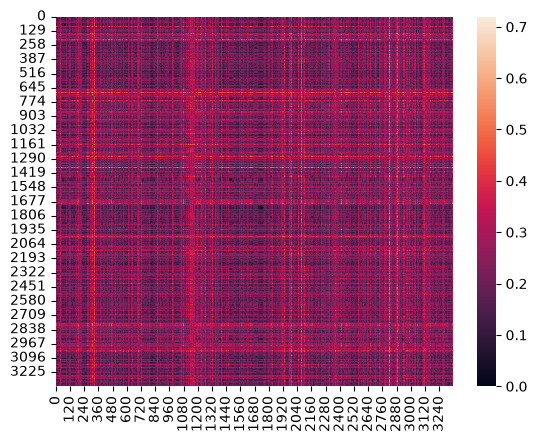

In [71]:
sns.heatmap(D)

In [72]:
from sklearn.neighbors import NearestNeighbors

In [73]:
def optimal_epsilon_plot(dist_m, min_samples):
    plt.figure(figsize=(10, 10))

    nn = NearestNeighbors(n_neighbors=min_samples, metric="precomputed")
    nn.fit(dist_m)
    distances, indicies = nn.kneighbors(dist_m)
    k_distances = distances[:, -1]
    k_distances = np.sort(k_distances)
    plt.plot(k_distances)

    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"{min_samples}-NN distance")
    plt.title("k-distance Graph for DBScan")
    plt.grid(True)
    plt.show()

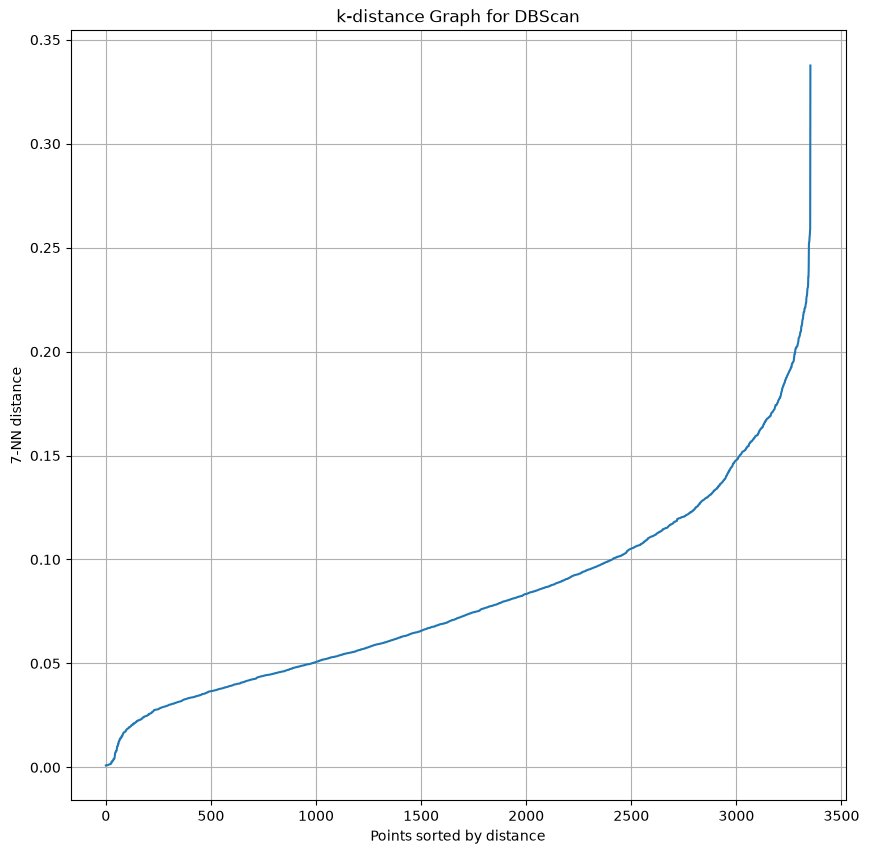

In [74]:
optimal_epsilon_plot(D, 7)

We can see the even argument embeddings have the same behaviour between each other. Maybe we can use as a basis for the arguments.

### Clustering similar arguments

In [75]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [76]:
legal_args_cluster = DBSCAN(eps=0.05, min_samples=10, metric="precomputed").fit_predict(D)
silhouette_score(D, legal_args_cluster, metric="precomputed")

-0.1294492781162262

In [77]:
base_premise_df["cluster"] = legal_args_cluster

In [78]:
base_premise_df[base_premise_df["cluster"] != -1]

,doc_id,arg_id,arg_text,arg_type,arg_argtype,cluster
7,116062204,P24,"Так, ОСОБА_5 , за попередньою змовою та спільн...",PREMISE,BASE_PREMISE,0
9,116062204,C26,Дії ОСОБА_5 та ОСОБА_6 кваліфіковані за ч.4...,CLAIM,INTERMEDIATE_CONCLUSION,1
10,116062204,P27,18 грудня 2023 року між прокурором Чугуївськог...,PREMISE,BASE_PREMISE,3
13,116062204,P29,"Крім того, 18 грудня 2023 року між прокурором ...",PREMISE,BASE_PREMISE,3
16,116062204,P32,"Відповідно до правил ст.ст. 468, 469 КПК Украї...",PREMISE,BASE_PREMISE,2
...,...,...,...,...,...,...
3305,117516936,C07,Долю речових доказів суд вирішує в порядку ст....,CLAIM,FINAL_CONCLUSION,4
3308,117516936,P24,"Керуючись ст.ст. 100, 314, 373, 374, 468, 469,...",PREMISE,BASE_PREMISE,5
3309,117516936,C13,"укладення угоди сторонами є добровільним, тобт...",CLAIM,INTERMEDIATE_CONCLUSION,3
3324,117556435,P15,Питання про долю речових доказів суд вирішує в...,PREMISE,BASE_PREMISE,4


# Von Misses-Fisher Distribution check

In [32]:
base_premise_df = base_premise_df.reset_index()

In [33]:
base_premises_embeddings.shape, base_premise_df.shape

((2379, 384), (2379, 7))

In [34]:
sampled_base_premise_df = base_premise_df[base_premise_df["cluster"] == 10]
sampled_base_premise_indexes = sampled_base_premise_df.index
sampled_base_premise_embeddings = base_premises_embeddings[sampled_base_premise_indexes]

In [35]:
sampled_base_premise_embeddings.shape

(36, 384)

In [36]:
norms = np.linalg.norm(sampled_base_premise_embeddings, axis=1)

norms.mean(), norms.std(), norms.min(), norms.max()

(np.float32(1.0),
 np.float32(3.5817934e-08),
 np.float32(0.99999994),
 np.float32(1.0000001))

In [37]:
from scipy.stats import vonmises_fisher

In [38]:
X = sampled_base_premise_embeddings.astype(np.float64)
n,d = X.shape

In [39]:
n,d

(36, 384)

In [40]:
R = X.sum(axis=0)
R_norm = np.linalg.norm(R)

mu_hat = R / R_norm
R_bar = R_norm / n

In [41]:
R_bar

np.float64(0.9509354356971449)

In [42]:
R_norm

np.float64(34.23367568509722)

In [43]:
cos_to_mean = sampled_base_premise_embeddings @ mu_hat

In [44]:
np.quantile(cos_to_mean, [0, .01, .05, .25, .5, .75, .95, .99, 1])

array([0.91295129, 0.9132046 , 0.91482955, 0.93667923, 0.95202427,
       0.96455669, 0.98567929, 0.98688928, 0.98720457])

In [45]:
import numpy as np
from scipy.stats import vonmises_fisher

X = sampled_base_premise_embeddings.astype(np.float64)

n, d = X.shape

R = X.sum(axis=0)
R_norm = np.linalg.norm(R)

mu_hat = R / R_norm
R_bar = R_norm / n

kappa_hat = (
    R_bar * (d - R_bar**2)
    / (1 - R_bar**2)
)

X_sim = vonmises_fisher(
    mu_hat,
    kappa_hat
).rvs(
    size=n,
    random_state=np.random.default_rng(42)
)

t_obs = X @ mu_hat
t_sim = X_sim @ mu_hat

print("Observed")
print(
    np.quantile(
        t_obs,
        [0, .01, .05, .25, .5, .75, .95, .99, 1]
    )
)

print("\nvMF")
print(
    np.quantile(
        t_sim,
        [0, .01, .05, .25, .5, .75, .95, .99, 1]
    )
)

Observed
[0.91295129 0.9132046  0.91482955 0.93667923 0.95202427 0.96455669
 0.98567929 0.98688928 0.98720457]

vMF
[0.94047054 0.94067853 0.94313611 0.94882477 0.9515421  0.95284486
 0.95584787 0.95743945 0.95779129]


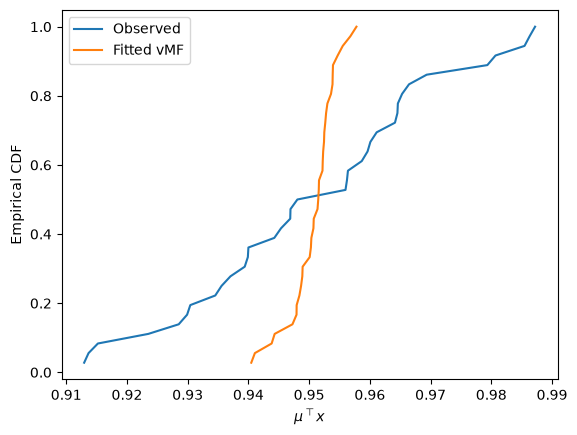

In [46]:
import matplotlib.pyplot as plt

obs_sorted = np.sort(t_obs)
sim_sorted = np.sort(t_sim)

p_obs = np.arange(1, len(obs_sorted) + 1) / len(obs_sorted)
p_sim = np.arange(1, len(sim_sorted) + 1) / len(sim_sorted)

plt.plot(obs_sorted, p_obs, label="Observed")
plt.plot(sim_sorted, p_sim, label="Fitted vMF")

plt.xlabel(r"$\mu^\top x$")
plt.ylabel("Empirical CDF")
plt.legend()
plt.show()

In [47]:
print("Observed variance:", np.var(t_obs))
print("vMF variance:", np.var(t_sim))

print(
    "Variance ratio:",
    np.var(t_obs) / np.var(t_sim)
)

Observed variance: 0.00040562806505558386
vMF variance: 1.4566768736148438e-05
Variance ratio: 27.84612513611134
